In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import f_oneway
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [73]:
df_condenacao_bovinos_bubalinos_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_condenacao_SE_ano.parquet')
df_estat_bovino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_se.parquet')

In [74]:
df_estat_bovino_abate_sudeste_bov = df_estat_bovino_abate_sudeste[df_estat_bovino_abate_sudeste['ESPECIE'].isin(['Bovino']) & df_estat_bovino_abate_sudeste['ANO'].isin([2021, 2022, 2023, 2024, 2025, 2026])]
print(df_estat_bovino_abate_sudeste_bov)

         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA ESPECIE  \
0       2025    8             MG               Araguari        Bovino  Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino  Bovino   
2       2025    6             MG          Cascalho Rico        Bovino  Bovino   
3       2021    2             MG         Estrela do Sul        Bovino  Bovino   
4       2021    2             MG          Campina Verde        Bovino  Bovino   
...      ...  ...            ...                    ...           ...     ...   
516640  2021    1             MG         Carmo De Minas  Bovino Macho  Bovino   
516641  2021    1             MG               Oliveira  Bovino Macho  Bovino   
516642  2021    1             MG           Delfinópolis  Bovino Femea  Bovino   
516643  2021    1             MG                Juruaia  Bovino Femea  Bovino   
516644  2021    1             MG       Cabeceira Grande  Bovino Femea  Bovino   

                 Sexo  QUAN

In [75]:
df_condenacao_bovinos_bubalinos_sudeste = df_condenacao_bovinos_bubalinos_sudeste[df_condenacao_bovinos_bubalinos_sudeste['ESPECIE'].isin(['Bovino']) & df_condenacao_bovinos_bubalinos_sudeste['ANO'].isin([2021, 2022, 2023, 2024, 2025, 2026])]
print(df_condenacao_bovinos_bubalinos_sudeste)

         MES_ANO UF_PROCEDENCIA ESPECIE    PARTE_AFETADA  \
0     2022-01-01             RJ  Bovino        Intestino   
1     2021-03-01             MG  Bovino          Carcaça   
2     2024-04-01             MG  Bovino          Carcaça   
3     2025-04-01             SP  Bovino          Carcaça   
4     2025-04-01             SP  Bovino  Quarto Traseiro   
...          ...            ...     ...              ...   
72820 2023-10-01             ES  Bovino          Carcaça   
72821 2024-11-01             MG  Bovino      Pés(mocotó)   
72822 2025-11-01             MG  Bovino             Rins   
72823 2021-12-01             ES  Bovino             Rins   
72824 2023-12-01             SP  Bovino         Pâncreas   

                                             DIAGNOSTICO  \
0                 CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
1      SEPTICEMIA                                    ...   
2                                   ABSCESSO (MAMÍFEROS)   
3                             ADERÊNCIA

In [76]:
#Agrupa pela coluna ESPECIE e soma os valores da coluna TOTAL_PARTES_AFETADAS
df_condenacao_bovinos_bubalinos_sudeste.groupby([ 'ANO', 'ESPECIE'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()

,ANO,ESPECIE,TOTAL_PARTES_AFETADAS
0,2021,Bovino,978564
1,2022,Bovino,1435987
2,2023,Bovino,1213943
3,2024,Bovino,1098005
4,2025,Bovino,1027716
5,2026,Bovino,239732


In [77]:
df_condenacao_bovinos_bubalinos_sudeste.groupby([ 'PARTE_AFETADA'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()

,PARTE_AFETADA,TOTAL_PARTES_AFETADAS
0,Baço,74603
1,Cabeça,236243
2,Carcaça,233394
3,Cauda(Rabo),32199
4,Coração,90336
5,Cérebro(Miolo),3279982
6,Diafragma,45045
7,Estômago,59690
8,Esôfago,64391
9,Fígado,244577


In [78]:
df_condenacao_bovinos_bubalinos_sudeste = df_condenacao_bovinos_bubalinos_sudeste[df_condenacao_bovinos_bubalinos_sudeste['PARTE_AFETADA'].isin(['Carcaça', 'Meia Carcaça'])]
print(df_condenacao_bovinos_bubalinos_sudeste)

         MES_ANO UF_PROCEDENCIA ESPECIE PARTE_AFETADA  \
1     2021-03-01             MG  Bovino       Carcaça   
2     2024-04-01             MG  Bovino       Carcaça   
3     2025-04-01             SP  Bovino       Carcaça   
5     2022-06-01             MG  Bovino       Carcaça   
29    2024-10-01             MG  Bovino       Carcaça   
...          ...            ...     ...           ...   
72794 2024-07-01             MG  Bovino       Carcaça   
72809 2021-04-01             MG  Bovino       Carcaça   
72810 2023-04-01             MG  Bovino       Carcaça   
72817 2025-07-01             MG  Bovino       Carcaça   
72820 2023-10-01             ES  Bovino       Carcaça   

                                             DIAGNOSTICO  \
1      SEPTICEMIA                                    ...   
2                                   ABSCESSO (MAMÍFEROS)   
3                             ADERÊNCIA DE PLEURA (SECA)   
5                          TUBERCULOSE (NOTIFICAÇÃO SIF)   
29         MATE

In [79]:
df_condenacao_bovinos_bubalinos_sudeste.groupby([ 'DESTINO_CONDENACAO'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()

,DESTINO_CONDENACAO,TOTAL_PARTES_AFETADAS
0,ABATE SANITÁRIO,274
1,ANIMAIS COLETADOS MONITORAMENTO ATIVO,44
2,APREENSÃO CAUTELAR,3
3,APREENSÃO CAUTELAR (PRODUTO),1
4,AUTOCLAVAGEM/INCINERAÇÃO (ANIMAIS),333
5,CONDENAÇÃO (AUTOCONTROLE),845
6,CONDENAÇÃO (AUTOCONTROLE) (PRODUTO),3
7,CONDENAÇÃO (POST MORTEM),5523
8,CONDENAÇÃO PARCIAL (POST MORTEM),17613
9,CONDENAÇÃO TOTAL (POST MORTEM),6120


In [80]:
df_condenacao_bovinos_bubalinos_sudeste = df_condenacao_bovinos_bubalinos_sudeste[df_condenacao_bovinos_bubalinos_sudeste['DESTINO_CONDENACAO'].isin(['AUTOCLAVAGEM/INCINERAÇÃO (ANIMAIS)', 'CONDENAÇÃO (AUTOCONTROLE)', 'CONDENAÇÃO (AUTOCONTROLE) (PRODUTO)', 'CONDENAÇÃO (POST MORTEM)', 'CONDENAÇÃO PARCIAL (POST MORTEM)', 'CONDENAÇÃO TOTAL (POST MORTEM)'])]
print(df_condenacao_bovinos_bubalinos_sudeste)

         MES_ANO UF_PROCEDENCIA ESPECIE PARTE_AFETADA  \
2     2024-04-01             MG  Bovino       Carcaça   
42    2022-05-01             MG  Bovino       Carcaça   
43    2022-05-01             MG  Bovino       Carcaça   
128   2025-12-01             MG  Bovino       Carcaça   
174   2024-10-01             MG  Bovino       Carcaça   
...          ...            ...     ...           ...   
72709 2023-04-01             MG  Bovino       Carcaça   
72710 2024-04-01             MG  Bovino       Carcaça   
72765 2024-10-01             MG  Bovino       Carcaça   
72794 2024-07-01             MG  Bovino       Carcaça   
72810 2023-04-01             MG  Bovino       Carcaça   

                            DIAGNOSTICO                DESTINO_CONDENACAO  \
2                  ABSCESSO (MAMÍFEROS)         CONDENAÇÃO (AUTOCONTROLE)   
42                 ABSCESSO (MAMÍFEROS)          CONDENAÇÃO (POST MORTEM)   
43                   LESÃO INFLAMATÓRIA    CONDENAÇÃO TOTAL (POST MORTEM)   
128    

In [99]:
df_soma = df_condenacao_bovinos_bubalinos_sudeste.groupby(['ANO'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()
print(df_soma)

    ANO  TOTAL_PARTES_AFETADAS
0  2021                   3246
1  2022                   3022
2  2023                   3544
3  2024                   8812
4  2025                   9658
5  2026                   2155


In [81]:
df_estat_bovino_abate_sudeste_bov.info()

<class 'pandas.core.frame.DataFrame'>
Index: 59977 entries, 0 to 516644
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ANO                    59977 non-null  int64 
 1   MES                    59977 non-null  int64 
 2   UF_PROCEDENCIA         59977 non-null  object
 3   MUNICIPIO_PROCEDENCIA  59977 non-null  object
 4   CATEGORIA              59977 non-null  object
 5   ESPECIE                59977 non-null  object
 6   Sexo                   59977 non-null  object
 7   QUANTIDADE             59977 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 4.1+ MB


In [82]:
df_condenacao_bovinos_bubalinos_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4874 entries, 2 to 72810
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   MES_ANO                4874 non-null   datetime64[ns]
 1   UF_PROCEDENCIA         4874 non-null   object        
 2   ESPECIE                4874 non-null   object        
 3   PARTE_AFETADA          4874 non-null   object        
 4   DIAGNOSTICO            4874 non-null   object        
 5   DESTINO_CONDENACAO     4874 non-null   object        
 6   TOTAL_PARTES_AFETADAS  4874 non-null   int64         
 7   ANO                    4874 non-null   int32         
 8   MES                    4874 non-null   int32         
dtypes: datetime64[ns](1), int32(2), int64(1), object(5)
memory usage: 342.7+ KB


In [71]:
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste.copy()

colunas_texto = ["DIAGNOSTICO", "PARTE_AFETADA"]

base_carcacas[colunas_texto] = (
    base_carcacas[colunas_texto]
    .astype("string")
    .apply(lambda coluna: coluna.str.strip())
)

# Ajuste os textos conforme aparecem na sua tabela
base_carcacas = base_carcacas[
    base_carcacas["PARTE_AFETADA"].isin(["Carcaça", "Meia Carcaça"])
].copy()

base_carcacas["TOTAL_PARTES_AFETADAS"] = pd.to_numeric(
    base_carcacas["TOTAL_PARTES_AFETADAS"],
    errors="coerce"
)

resumo_diagnosticos = (
    base_carcacas
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
10        1                      ALTERAÇÃO RESTRITA               9306   
28        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR               7438   
50        3                        LESÃO TRAUMÁTICA               2864   
29        4       CONTAMINAÇÃO NÃO GASTROINTESTINAL               2500   
9         5        ALTERAÇÃO LINFÁTICA INESPECÍFICA               1119   

    percentual_do_total  
10                30.57  
28                24.44  
50                 9.41  
29                 8.21  
9                  3.68  


In [72]:
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
base_carcacas["DIAGNOSTICO"] = (
    base_carcacas["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    base_carcacas
    .dropna(subset=["DIAGNOSTICO"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
10        1                      ALTERAÇÃO RESTRITA               9306   
28        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR               7438   
50        3                        LESÃO TRAUMÁTICA               2864   
29        4       CONTAMINAÇÃO NÃO GASTROINTESTINAL               2500   
9         5        ALTERAÇÃO LINFÁTICA INESPECÍFICA               1119   

    percentual_do_total  
10                30.57  
28                24.44  
50                 9.41  
29                 8.21  
9                  3.68  


C:\Users\thami\AppData\Local\Temp\ipykernel_15564\535956197.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  base_carcacas["DIAGNOSTICO"] = (


In [159]:
#calculo do diagnóstico mais frequente por UF e ano, considerando apenas carcaças e meias carcaças
base_analise = df_condenacao_bovinos_bubalinos_sudeste[
    [
        "ANO",
        "UF_PROCEDENCIA",
        "DIAGNOSTICO",
        "TOTAL_PARTES_AFETADAS"
    ]
].copy()

base_analise["DIAGNOSTICO"] = (
    base_analise["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

base_analise["TOTAL_PARTES_AFETADAS"] = pd.to_numeric(
    base_analise["TOTAL_PARTES_AFETADAS"],
    errors="coerce"
)

causas_por_uf_ano = (
    base_analise
    .dropna(
        subset=[
            "ANO",
            "UF_PROCEDENCIA",
            "DIAGNOSTICO",
            "TOTAL_PARTES_AFETADAS"
        ]
    )
    .groupby(
        #["ANO", "DIAGNOSTICO"],
        ["ANO", "UF_PROCEDENCIA", "DIAGNOSTICO"],
        as_index=False
    )
    .agg(total_partes_afetadas=("TOTAL_PARTES_AFETADAS", "sum"))
)

# Participação do diagnóstico entre todas as partes afetadas daquela UF e ano
causas_por_uf_ano["percentual_na_uf_ano"] = (
    causas_por_uf_ano["total_partes_afetadas"]
    / causas_por_uf_ano.groupby(
        #["ANO"]
        ["ANO", "UF_PROCEDENCIA"]
    )["total_partes_afetadas"].transform("sum")
    * 100
).round(2)

# Mantém o diagnóstico mais frequente de cada UF em cada ano.
# Mantém mais de uma linha em caso de empate.
causa_principal_por_uf_ano = causas_por_uf_ano.loc[
    causas_por_uf_ano["total_partes_afetadas"].eq(
        causas_por_uf_ano.groupby(
            #["ANO"]
            ["ANO", "UF_PROCEDENCIA"]
        )["total_partes_afetadas"].transform("max")
    )
].sort_values(["ANO", "UF_PROCEDENCIA"])

print(causa_principal_por_uf_ano)

      ANO UF_PROCEDENCIA                             DIAGNOSTICO  \
2    2021             ES                      ALTERAÇÃO RESTRITA   
42   2021             MG                        LESÃO TRAUMÁTICA   
67   2021             RJ  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
85   2021             SP  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
109  2022             ES                   LESÕES TUBERCULÓSICAS   
134  2022             MG                        LESÃO TRAUMÁTICA   
155  2022             RJ                        LESÃO TRAUMÁTICA   
169  2022             SP  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
193  2023             ES  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
229  2023             MG                        LESÃO TRAUMÁTICA   
250  2023             RJ                        LESÃO TRAUMÁTICA   
266  2023             SP  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
289  2024             ES  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
309  2024             MG                      AL

In [160]:
#calculo do diagnóstico mais frequente por UF e ano, considerando apenas carcaças e meias carcaças
base_analise = df_condenacao_bovinos_bubalinos_sudeste[
    [
        "ANO",
        #"UF_PROCEDENCIA",
        "DIAGNOSTICO",
        "TOTAL_PARTES_AFETADAS"
    ]
].copy()

base_analise["DIAGNOSTICO"] = (
    base_analise["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

base_analise["TOTAL_PARTES_AFETADAS"] = pd.to_numeric(
    base_analise["TOTAL_PARTES_AFETADAS"],
    errors="coerce"
)

causas_por_ano = (
    base_analise
    .dropna(
        subset=[
            "ANO",
            #"UF_PROCEDENCIA",
            "DIAGNOSTICO",
            "TOTAL_PARTES_AFETADAS"
        ]
    )
    .groupby(
        ["ANO", "DIAGNOSTICO"],
        #["ANO", "UF_PROCEDENCIA", "DIAGNOSTICO"],
        as_index=False
    )
    .agg(total_partes_afetadas=("TOTAL_PARTES_AFETADAS", "sum"))
)

# Participação do diagnóstico entre todas as partes afetadas daquela UF e ano
causas_por_ano["percentual_no_ano"] = (
    causas_por_ano["total_partes_afetadas"]
    / causas_por_ano.groupby(
        ["ANO"]
        #["ANO", "UF_PROCEDENCIA"]
    )["total_partes_afetadas"].transform("sum")
    * 100
).round(2)

# Mantém o diagnóstico mais frequente de cada UF em cada ano.
# Mantém mais de uma linha em caso de empate.
causa_principal_por_ano = causas_por_ano.loc[
    causas_por_ano["total_partes_afetadas"].eq(
        causas_por_ano.groupby(
            ["ANO"]
            #["ANO", "UF_PROCEDENCIA"]
        )["total_partes_afetadas"].transform("max")
    )
].sort_values(["ANO"])

print(causa_principal_por_ano)

      ANO                             DIAGNOSTICO  total_partes_afetadas  \
19   2021  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                    800   
74   2022  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                    716   
135  2023                        LESÃO TRAUMÁTICA                   1063   
163  2024                      ALTERAÇÃO RESTRITA                   2993   
211  2025                      ALTERAÇÃO RESTRITA                   4914   
261  2026                      ALTERAÇÃO RESTRITA                   1085   

     percentual_no_ano  
19               24.65  
74               23.69  
135              29.99  
163              33.97  
211              50.88  
261              50.35  


In [103]:
ano = 2021
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
19        1  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                800   
34        2                        LESÃO TRAUMÁTICA                461   
1         3                    ABSCESSO (MAMÍFEROS)                316   
6         4        ALTERAÇÃO LINFÁTICA INESPECÍFICA                305   
36        5                   LESÕES TUBERCULÓSICAS                181   

    percentual_do_total  
19                24.65  
34                14.20  
1                  9.74  
6                  9.40  
36                 5.58  


In [104]:
ano = 2022
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
17        1  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                716   
27        2                        LESÃO TRAUMÁTICA                587   
5         3        ALTERAÇÃO LINFÁTICA INESPECÍFICA                279   
29        4                   LESÕES TUBERCULÓSICAS                245   
0         5                    ABSCESSO (MAMÍFEROS)                158   

    percentual_do_total  
17                23.69  
27                19.42  
5                  9.23  
29                 8.11  
0                  5.23  


In [105]:
ano = 2023
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
29        1                        LESÃO TRAUMÁTICA               1063   
19        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                741   
16        3                     CISTICERCOSE BOVINA                248   
27        4                      LESÃO INFLAMATÓRIA                218   
1         5                    ABSCESSO (MAMÍFEROS)                210   

    percentual_do_total  
29                29.99  
19                20.91  
16                 7.00  
27                 6.15  
1                  5.93  


In [106]:
ano = 2023
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
29        1                        LESÃO TRAUMÁTICA               1063   
19        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                741   
16        3                     CISTICERCOSE BOVINA                248   
27        4                      LESÃO INFLAMATÓRIA                218   
1         5                    ABSCESSO (MAMÍFEROS)                210   

    percentual_do_total  
29                29.99  
19                20.91  
16                 7.00  
27                 6.15  
1                  5.93  


In [107]:
ano = 2024
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
7         1                      ALTERAÇÃO RESTRITA               2993   
17        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR               2603   
18        3       CONTAMINAÇÃO NÃO GASTROINTESTINAL               1370   
29        4                        LESÃO TRAUMÁTICA                291   
28        5                      LESÃO INFLAMATÓRIA                197   

    percentual_do_total  
7                 33.97  
17                29.54  
18                15.55  
29                 3.30  
28                 2.24  


In [108]:
ano = 2025
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
6         1                      ALTERAÇÃO RESTRITA               4914   
18        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR               2084   
19        3       CONTAMINAÇÃO NÃO GASTROINTESTINAL                760   
31        4                        LESÃO TRAUMÁTICA                369   
33        5                   LESÕES TUBERCULÓSICAS                213   

    percentual_do_total  
6                 50.88  
18                21.58  
19                 7.87  
31                 3.82  
33                 2.21  


In [109]:
ano = 2026
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
carcaca_painel = base_carcacas.loc[base_carcacas["ANO"] == ano, ["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"]].copy()

carcaca_painel["DIAGNOSTICO"] = (
    carcaca_painel["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    carcaca_painel
    .dropna(subset=["DIAGNOSTICO", "TOTAL_PARTES_AFETADAS"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                             DIAGNOSTICO  total_condenacoes  \
4         1                      ALTERAÇÃO RESTRITA               1085   
10        2  CONTAMINAÇÃO GASTROINTESTINAL E BILIAR                494   
11        3       CONTAMINAÇÃO NÃO GASTROINTESTINAL                154   
17        4                        LESÃO TRAUMÁTICA                 93   
19        5                   LESÕES TUBERCULÓSICAS                 55   

    percentual_do_total  
4                 50.35  
10                22.92  
11                 7.15  
17                 4.32  
19                 2.55  


<H1>TAXA DE CONDENAÇÃO DE CARCAÇAS DE BOVINOS NO SUDESTE<H1>

In [110]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_condenacao_bovinos_bubalinos_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["TOTAL_PARTES_AFETADAS"]
      .sum()
      .sort_values("TOTAL_PARTES_AFETADAS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["TOTAL_PARTES_AFETADAS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_estado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["TOTAL_PARTES_AFETADAS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_estado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
0,ES,476325,888,0.19
1,MG,11129045,18487,0.17
2,RJ,131442,2786,2.12
3,SP,13502549,8276,0.06


<h2>Taxas de condenação/abate por ano</h2>

In [111]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_condenacao_bovinos_bubalinos_sudeste.groupby(["ANO"], as_index=False)["TOTAL_PARTES_AFETADAS"]
      .sum()
      .sort_values("TOTAL_PARTES_AFETADAS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["TOTAL_PARTES_AFETADAS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_ano = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["TOTAL_PARTES_AFETADAS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_ano

,ANO,Abatidos,Condenados,Percentual Condenados
0,2021,4061202,3246,0.08
1,2022,4545378,3022,0.07
2,2023,4658337,3544,0.08
3,2024,5125195,8812,0.17
4,2025,5593073,9658,0.17
5,2026,1256176,2155,0.17


<h2>ANALISE DE NORMALIDADE E HISTOGRAMAS<h2>

In [112]:
condenacao_consolidado = df_condenacao_bovinos_bubalinos_sudeste.groupby(['ANO', 'MES', 'UF_PROCEDENCIA'], as_index=False).agg(CONDENADO=("TOTAL_PARTES_AFETADAS", "sum"))
condenacao_consolidado

,ANO,MES,UF_PROCEDENCIA,CONDENADO
0,2021,2,ES,8
1,2021,2,MG,346
2,2021,2,RJ,4
3,2021,2,SP,76
4,2021,3,ES,29
...,...,...,...,...
239,2026,2,RJ,45
240,2026,2,SP,327
241,2026,3,MG,381
242,2026,3,RJ,63


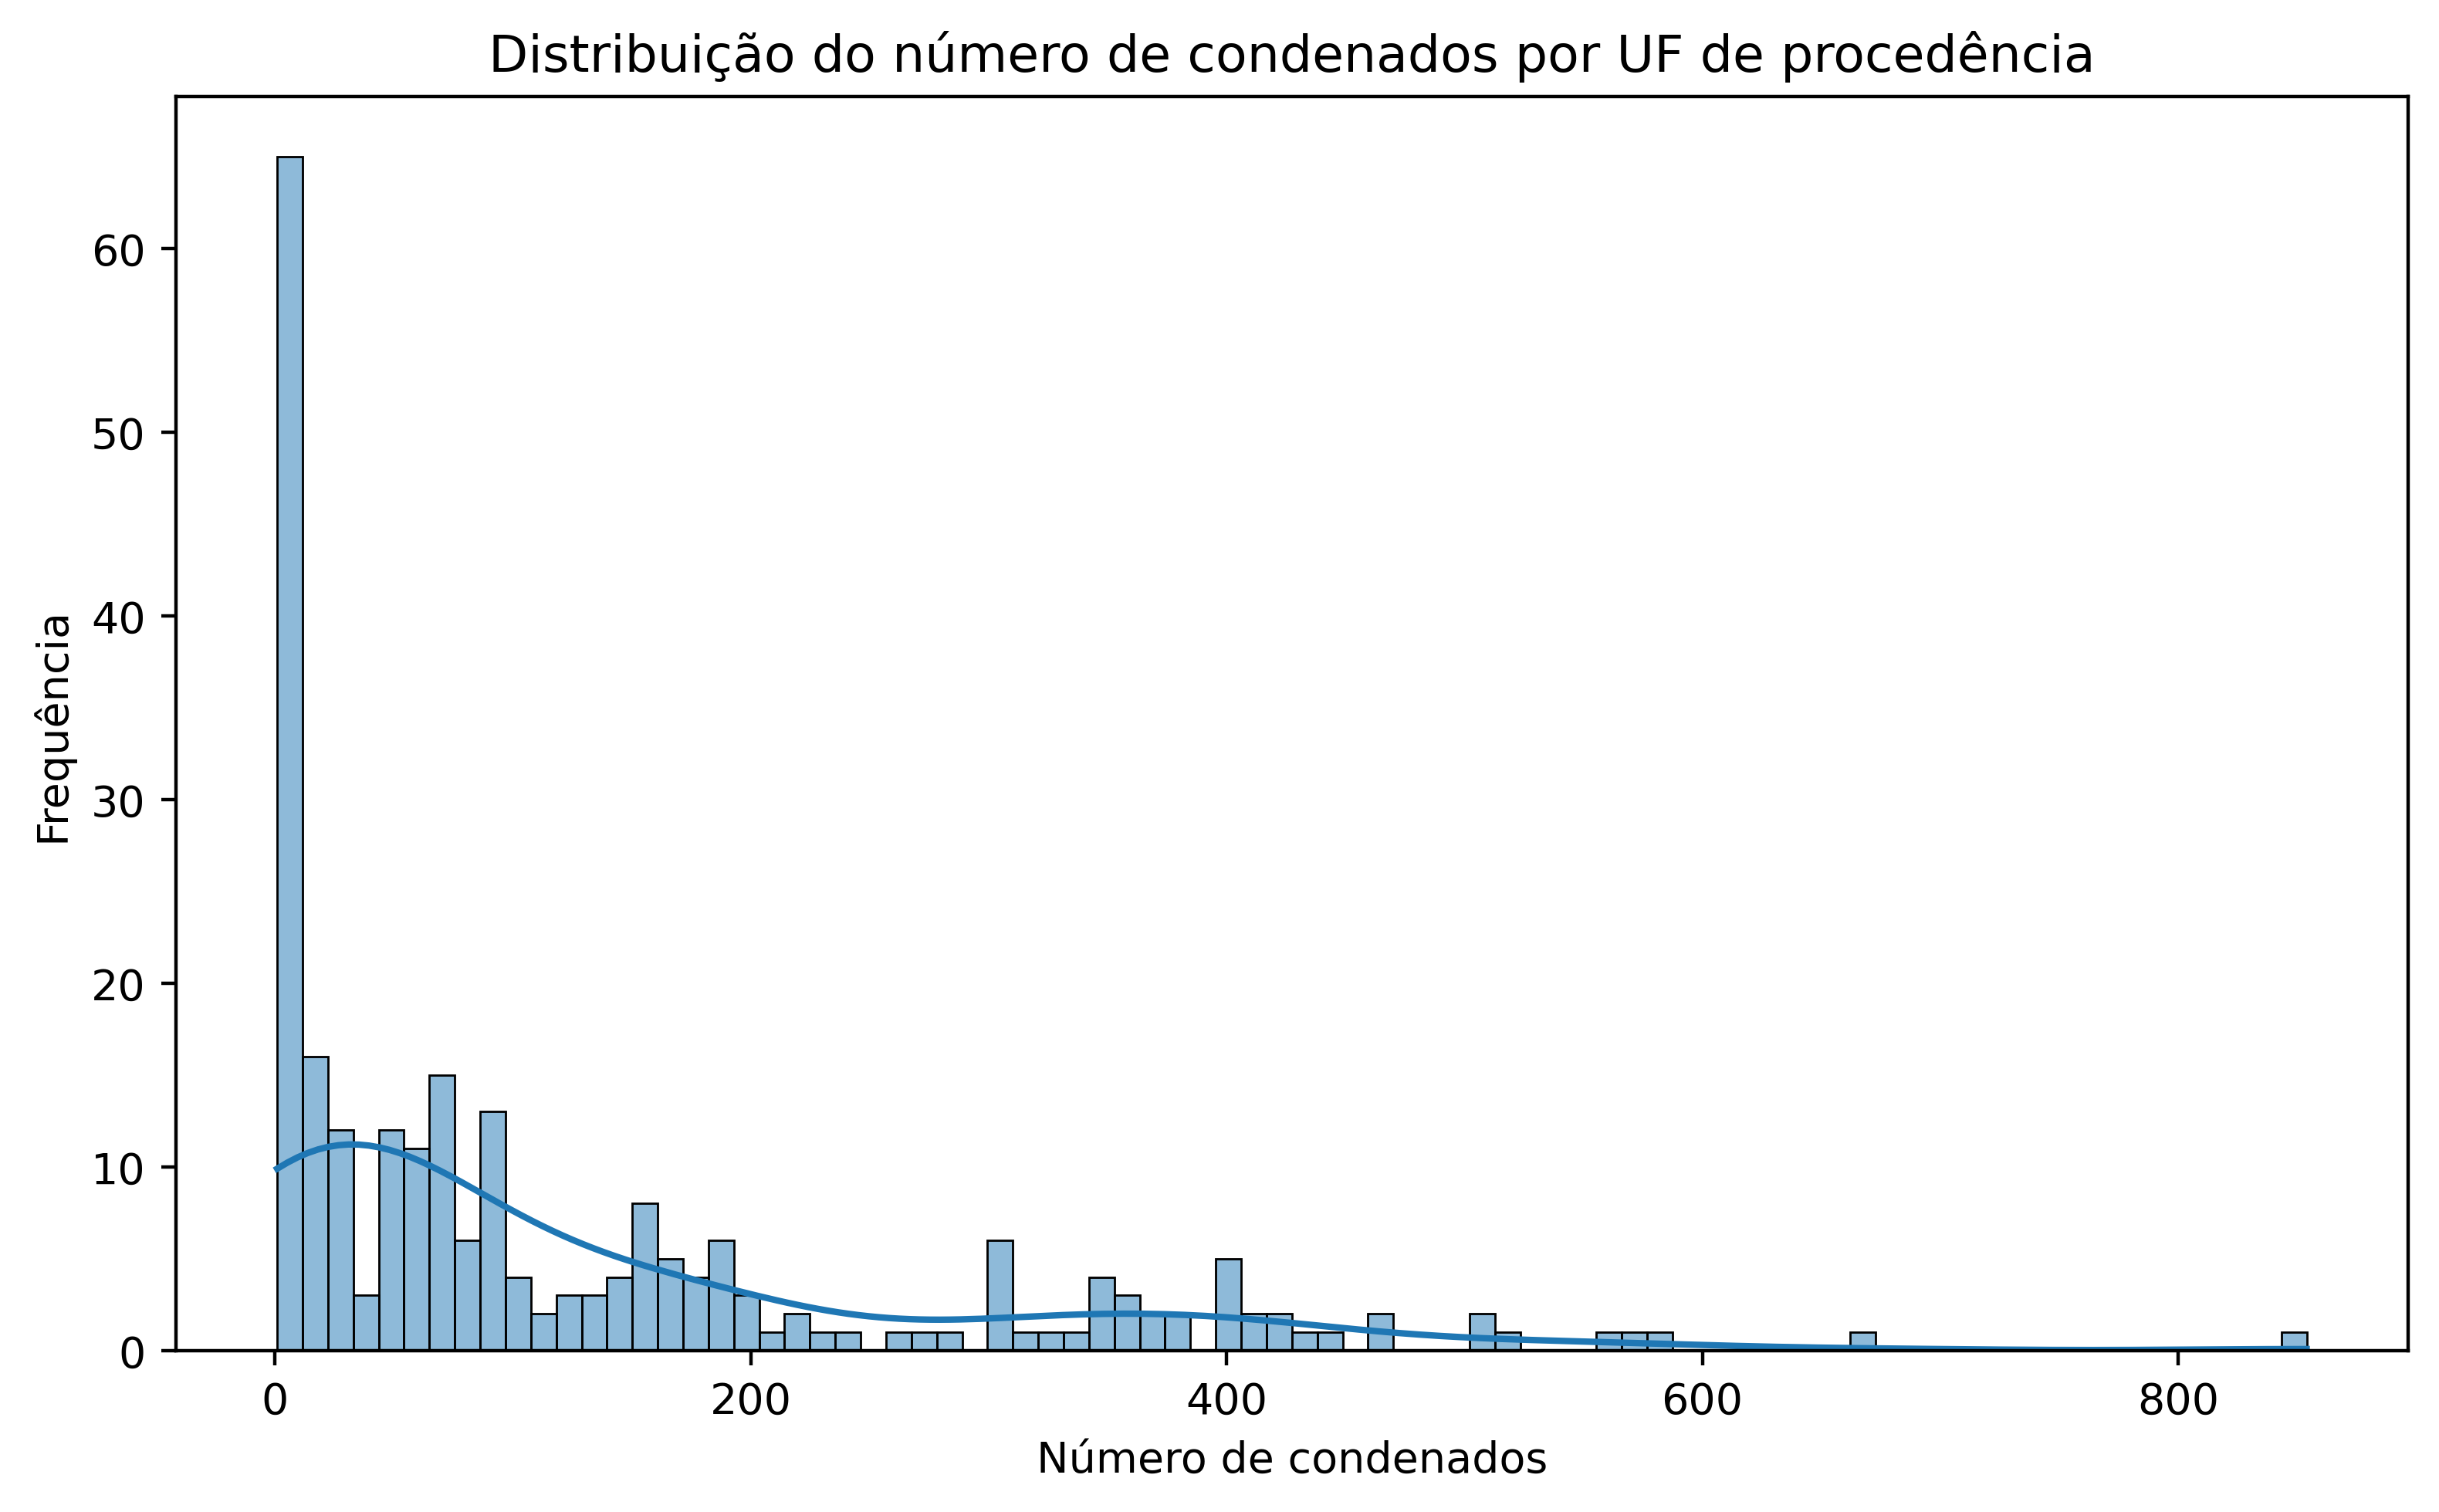

In [113]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=condenacao_consolidado,
    x="CONDENADO",
    bins=80,
    kde=True
)

pl.title("Distribuição do número de condenados por UF de procedência")
pl.xlabel("Número de condenados")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [114]:
from scipy.stats import shapiro

for uf, grupo in condenacao_consolidado.groupby("UF_PROCEDENCIA"):
    valores = grupo["CONDENADO"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )
    #os dados sendo p < 0,05 apresentam evidências suficientes para rejeitar a hipótese nula de normalidade, indicando que os dados não seguem uma distribuição normal.

ES: W = 0.7736; p = 0.0000
MG: W = 0.8787; p = 0.0000
RJ: W = 0.6675; p = 0.0000
SP: W = 0.6959; p = 0.0000


In [115]:
abate_consolidado = df_estat_bovino_abate_sudeste_bov.groupby(['ANO', 'MES', 'UF_PROCEDENCIA'], as_index=False).agg(ABATE=("QUANTIDADE", "sum"))
abate_consolidado

,ANO,MES,UF_PROCEDENCIA,ABATE
0,2021,1,ES,4230
1,2021,1,MG,121602
2,2021,1,RJ,2169
3,2021,1,SP,159299
4,2021,2,ES,5178
...,...,...,...,...
248,2026,3,ES,4364
249,2026,3,MG,188057
250,2026,3,RJ,1554
251,2026,3,SP,246487


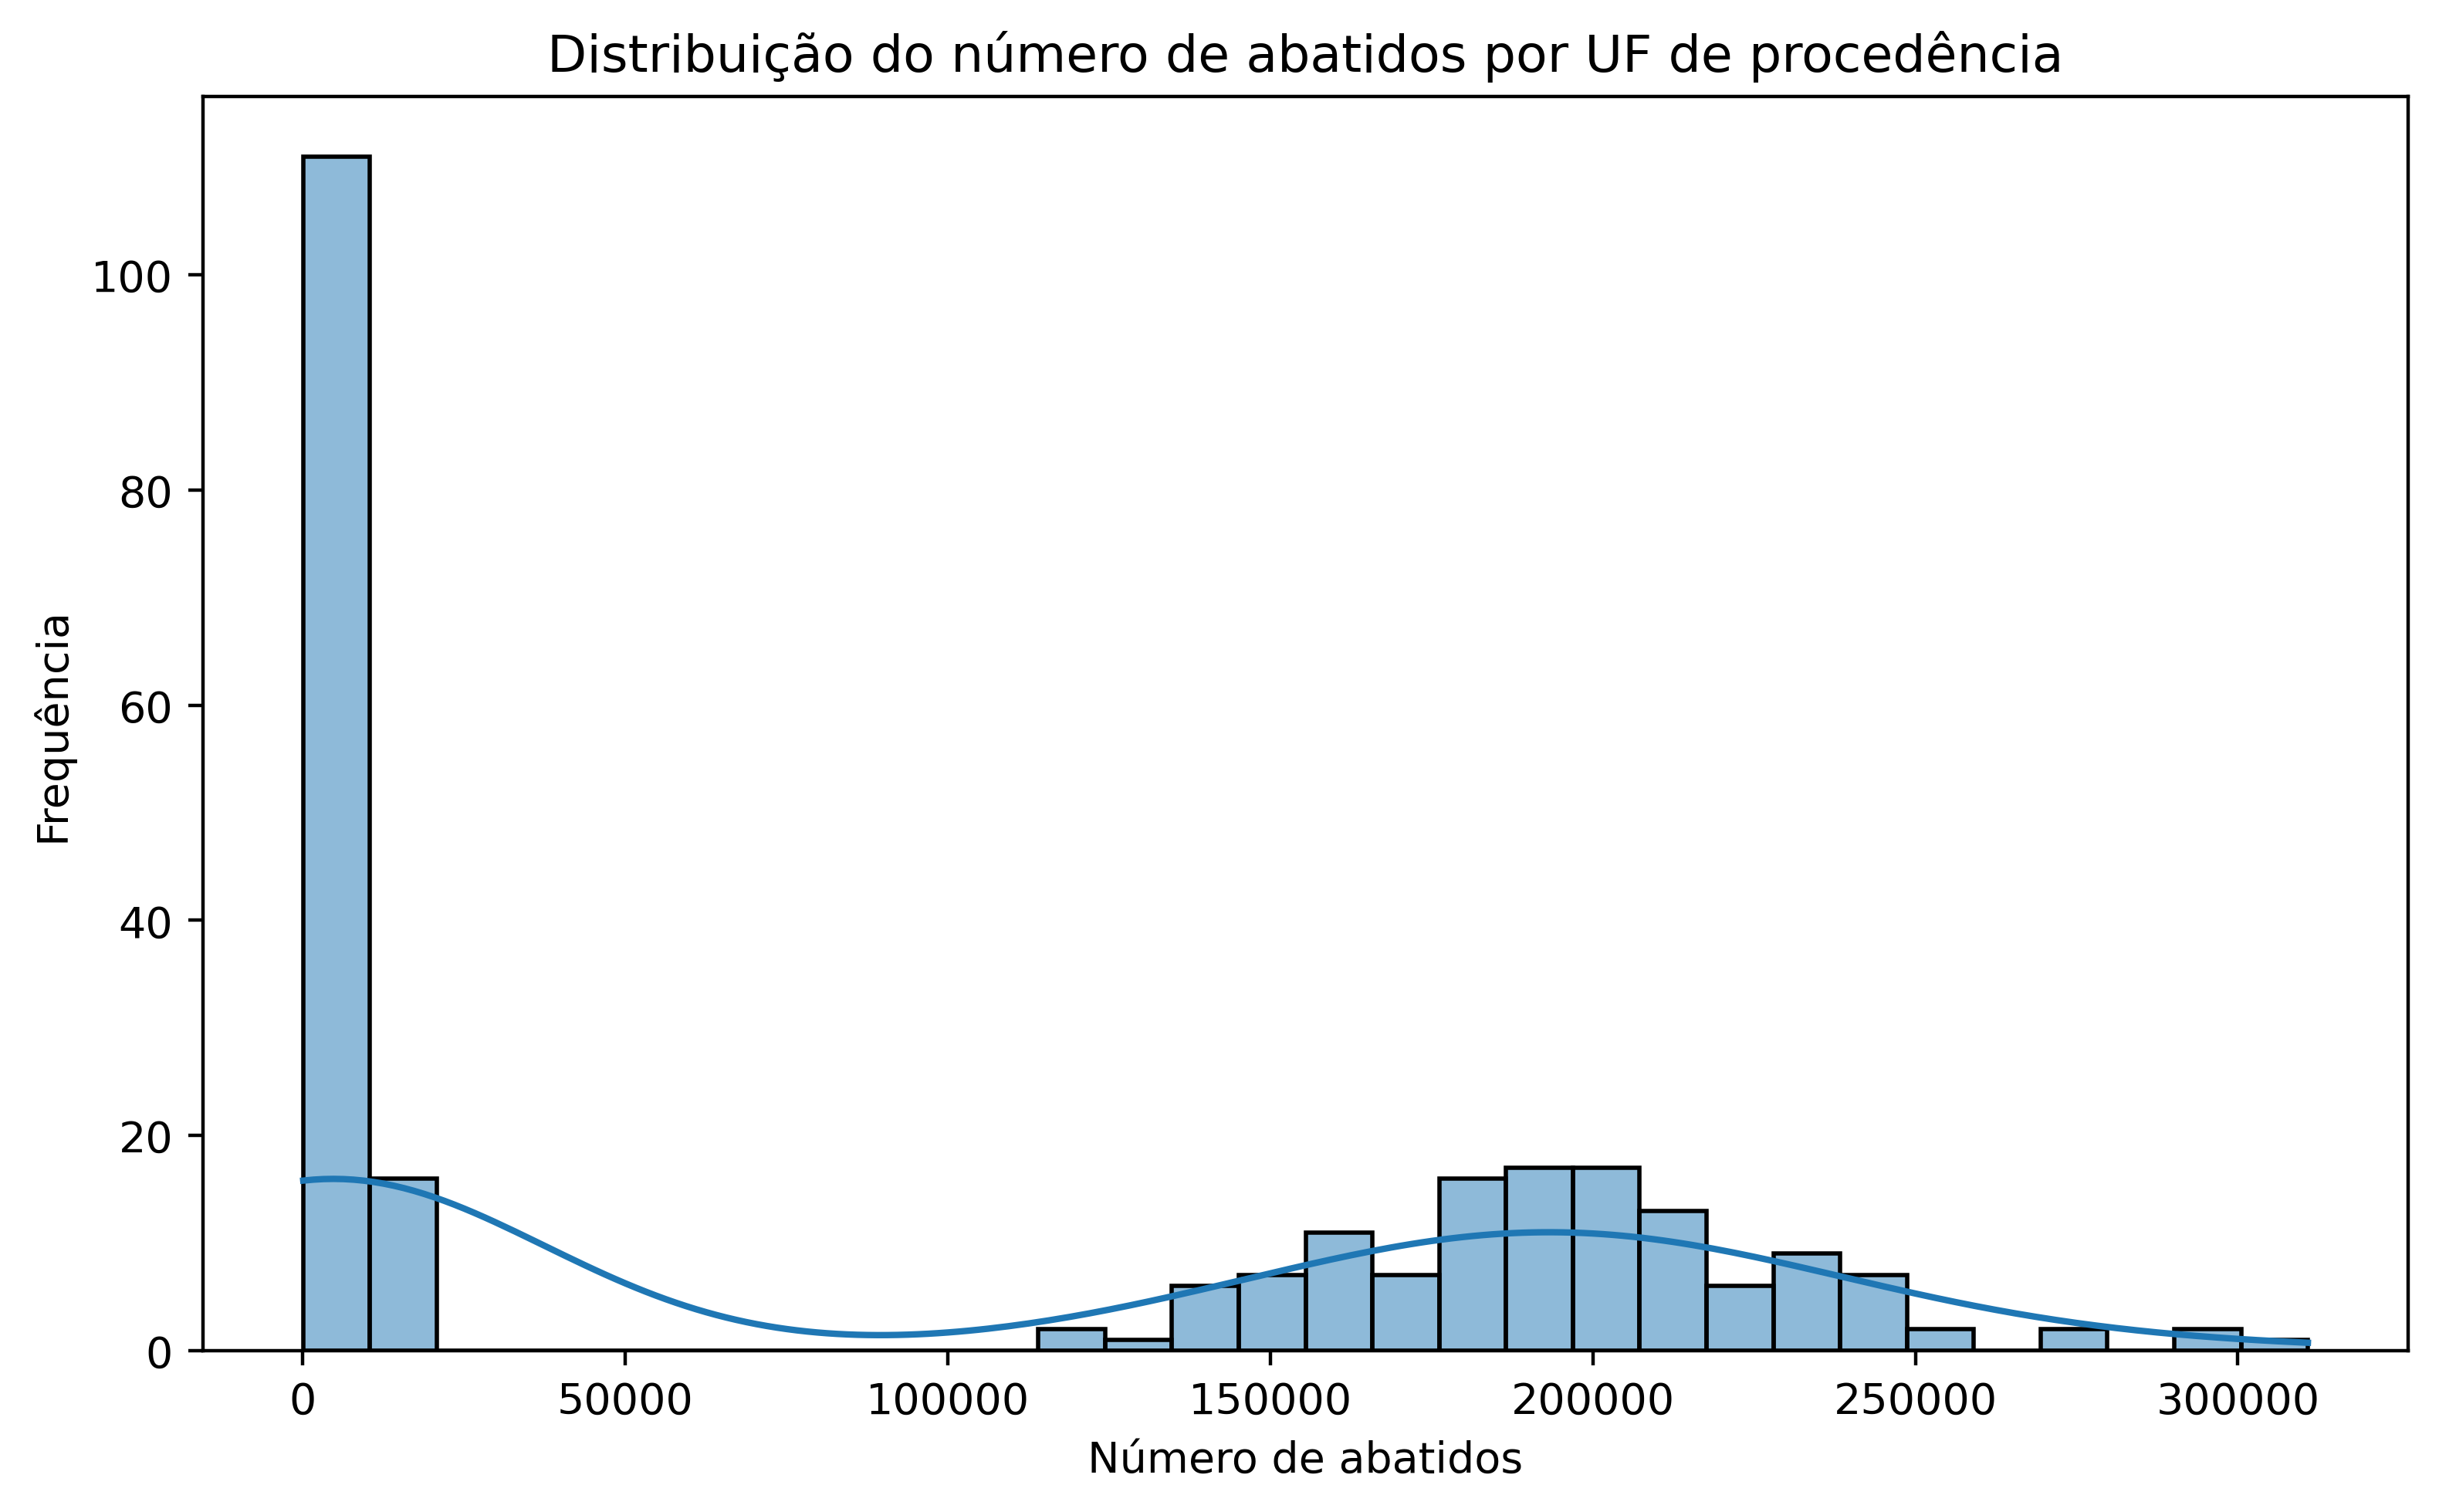

In [116]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=abate_consolidado,
    x="ABATE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos por UF de procedência")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [117]:
from scipy.stats import shapiro

for uf, grupo in abate_consolidado.groupby("UF_PROCEDENCIA"):
    valores = grupo["ABATE"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )

ES: W = 0.9466; p = 0.0085
MG: W = 0.7856; p = 0.0000
RJ: W = 0.9695; p = 0.1202
SP: W = 0.9771; p = 0.2893


In [118]:
dados_estat = pd.merge(condenacao_consolidado, abate_consolidado, on=['ANO', 'MES', 'UF_PROCEDENCIA'], how='right', validate='one_to_one')
dados_estat["percentual_condenados"] = (
    dados_estat["CONDENADO"] / dados_estat["ABATE"] * 100
).fillna(0)

#dados_estat["ABATE"] = dados_estat["ABATE"].fillna(0)
dados_estat["CONDENADO"] = dados_estat["CONDENADO"].fillna(0)

print(dados_estat.head(100))
dados_estat.to_excel("tabela_dadosestat.xlsx", index=False)

     ANO  MES UF_PROCEDENCIA  CONDENADO   ABATE  percentual_condenados
0   2021    1             ES        0.0    4230               0.000000
1   2021    1             MG        0.0  121602               0.000000
2   2021    1             RJ        0.0    2169               0.000000
3   2021    1             SP        0.0  159299               0.000000
4   2021    2             ES        8.0    5178               0.154500
..   ...  ...            ...        ...     ...                    ...
95  2022   12             SP       56.0  201885               0.027739
96  2023    1             ES       21.0    2842               0.738916
97  2023    1             MG      149.0  147402               0.101084
98  2023    1             RJ        8.0    2253               0.355082
99  2023    1             SP       51.0  195162               0.026132

[100 rows x 6 columns]


In [119]:
from scipy.stats import shapiro

for uf, grupo in dados_estat.groupby("UF_PROCEDENCIA"):
    valores = grupo["percentual_condenados"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )

ES: W = 0.8004; p = 0.0000
MG: W = 0.9426; p = 0.0050
RJ: W = 0.7259; p = 0.0000
SP: W = 0.7630; p = 0.0000


In [120]:
modelo_quasi = smf.glm(
    "CONDENADO + I(ABATE - CONDENADO) ~ C(UF_PROCEDENCIA) + C(ANO)",
    data=dados_estat,
    family=sm.families.Binomial()
).fit(scale="X2")

print(modelo_quasi.summary())

                           Generalized Linear Model Regression Results                           
Dep. Variable:     ['CONDENADO', 'I(ABATE - CONDENADO)']   No. Observations:                  253
Model:                                               GLM   Df Residuals:                      244
Model Family:                                   Binomial   Df Model:                            8
Link Function:                                     Logit   Scale:                       0.0091455
Method:                                             IRLS   Log-Likelihood:                -4840.2
Date:                                   Thu, 20 Aug 2026   Deviance:                       8296.5
Time:                                           19:03:26   Pearson chi2:                 9.00e+03
No. Iterations:                                       15   Pseudo R-squ. (CS):              1.000
Covariance Type:                               nonrobust                                         
                    

<h2>TESTE DE FRIEDMAN E WILCOXON<H2>

<H3>BASE PARA O CÁLCULO<H3>

In [121]:
dados_mes = abate_consolidado.merge(
    condenacao_consolidado,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Use somente se ausência de registro de condenação significar zero real
dados_mes["CONDENADO"] = dados_mes["CONDENADO"].fillna(0)

dados_mes["percentual_condenados"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

dados_mes

,ANO,MES,UF_PROCEDENCIA,ABATE,CONDENADO,percentual_condenados
0,2021,1,ES,4230,0.0,0.000000
1,2021,1,MG,121602,0.0,0.000000
2,2021,1,RJ,2169,0.0,0.000000
3,2021,1,SP,159299,0.0,0.000000
4,2021,2,ES,5178,8.0,0.154500
...,...,...,...,...,...,...
248,2026,3,ES,4364,0.0,0.000000
249,2026,3,MG,188057,381.0,0.202598
250,2026,3,RJ,1554,63.0,4.054054
251,2026,3,SP,246487,274.0,0.111162


In [122]:
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2021[uf] for uf in painel_2021.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(19.363636363636363), pvalue=np.float64(0.00022992009949067928))


In [123]:
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2021.columns, 2):
    teste = wilcoxon(
        painel_2021[uf1],
        painel_2021[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2021[uf1] - painel_2021[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2021    ES × MG   0.0703             0.0322  0.2109          False
1  2021    ES × RJ   0.0840             0.0508  0.2109          False
2  2021    ES × SP   0.0010             0.1113  0.0059           True
3  2021    MG × RJ   0.8799             0.0164  0.8799          False
4  2021    MG × SP   0.0010             0.0653  0.0059           True
5  2021    RJ × SP   0.0059             0.0770  0.0234           True


In [124]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2021

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
0  2021             ES        0.161781            0.0       0.650224
2  2021             RJ        0.118752            0.0       0.224972
1  2021             MG        0.114317            0.0       0.248059
3  2021             SP        0.044599            0.0       0.077676


In [151]:
causa_es_2021 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2021)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2021
diagnostico_alvo = causa_es_2021.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico_21 = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico_21[uf] for uf in painel_diagnostico_21.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(8.200000000000003), pvalue=np.float64(0.04205418289496618))


In [152]:
resultados = []

for uf1, uf2 in combinations(painel_diagnostico_21.columns, 2):
    teste = wilcoxon(
        painel_diagnostico_21[uf1],
        painel_diagnostico_21[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (
            painel_diagnostico_21[uf1] - painel_diagnostico_21[uf2]
        ).median()
    })

pos_hoc_diagnostico = pd.DataFrame(resultados)

pos_hoc_diagnostico["p_holm"] = multipletests(
    pos_hoc_diagnostico["p_bruto"],
    method="holm"
)[1]

pos_hoc_diagnostico["significativo"] = (
    pos_hoc_diagnostico["p_holm"] < 0.05
)

print(pos_hoc_diagnostico.round(4))

  comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0    ES × MG     0.25            -0.0907     1.0          False
1    ES × RJ     0.25            -0.1287     1.0          False
2    ES × SP     0.25            -0.0848     1.0          False
3    MG × RJ     0.25            -0.0532     1.0          False
4    MG × SP     1.00            -0.0053     1.0          False
5    RJ × SP     0.25             0.0590     1.0          False


In [126]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2022[uf] for uf in painel_2022.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(13.200000000000017), pvalue=np.float64(0.004223463658686329))


In [127]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2022.columns, 2):
    teste = wilcoxon(
        painel_2022[uf1],
        painel_2022[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2022[uf1] - painel_2022[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2022    ES × MG   0.2661             0.0165  0.5322          False
1  2022    ES × RJ   0.3804            -0.0179  0.5322          False
2  2022    ES × SP   0.0034             0.0998  0.0171           True
3  2022    MG × RJ   0.1514            -0.0671  0.4541          False
4  2022    MG × SP   0.0005             0.0634  0.0029           True
5  2022    RJ × SP   0.0049             0.1397  0.0195           True


In [128]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2022

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
2  2022             RJ        0.165882       0.000000       1.153213
0  2022             ES        0.133409       0.025625       0.265523
1  2022             MG        0.091818       0.074577       0.171628
3  2022             SP        0.029467       0.024844       0.079338


In [153]:
causa_es_2022 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2022)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2022
diagnostico_alvo = causa_es_2022.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico_22 = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico_22[uf] for uf in painel_diagnostico_22.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(9.000000000000002), pvalue=np.float64(0.029290886534888188))


In [154]:
resultados = []

for uf1, uf2 in combinations(painel_diagnostico_22.columns, 2):
    teste = wilcoxon(
        painel_diagnostico_22[uf1],
        painel_diagnostico_22[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (
            painel_diagnostico_22[uf1] - painel_diagnostico_22[uf2]
        ).median()
    })

pos_hoc_diagnostico = pd.DataFrame(resultados)

pos_hoc_diagnostico["p_holm"] = multipletests(
    pos_hoc_diagnostico["p_bruto"],
    method="holm"
)[1]

pos_hoc_diagnostico["significativo"] = (
    pos_hoc_diagnostico["p_holm"] < 0.05
)

print(pos_hoc_diagnostico.round(4))

c:\Users\thami\anaconda3\Lib\site-packages\scipy\stats\_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


  comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0    ES × MG     0.25            -0.0091     1.0          False
1    ES × RJ     1.00             0.0000     1.0          False
2    ES × SP     0.25            -0.0009     1.0          False
3    MG × RJ     0.25             0.0091     1.0          False
4    MG × SP     0.25             0.0079     1.0          False
5    RJ × SP     0.25            -0.0009     1.0          False


In [130]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2023[uf] for uf in painel_2023.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(32.80000000000001), pvalue=np.float64(3.5491940273859193e-07))


In [131]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2023.columns, 2):
    teste = wilcoxon(
        painel_2023[uf1],
        painel_2023[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2023[uf1] - painel_2023[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2023    ES × MG   0.0005             0.1355  0.0029           True
1  2023    ES × RJ   0.7334            -0.1061  0.7334          False
2  2023    ES × SP   0.0005             0.2140  0.0029           True
3  2023    MG × RJ   0.0005            -0.2315  0.0029           True
4  2023    MG × SP   0.0005             0.0701  0.0029           True
5  2023    RJ × SP   0.0005             0.3081  0.0029           True


In [132]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2023

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
2  2023             RJ        0.343659       0.229043       0.869565
0  2023             ES        0.243615       0.128430       0.738916
1  2023             MG        0.100589       0.073846       0.169630
3  2023             SP        0.035587       0.023500       0.052820


In [155]:
causa_es_2023 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2023)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2023
diagnostico_alvo = causa_es_2023.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico_23 = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico_23[uf] for uf in painel_diagnostico_23.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(6.600000000000001), pvalue=np.float64(0.08580108740012288))


In [134]:
ano = 2024

painel_2024 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2024[uf] for uf in painel_2024.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(32.400000000000006), pvalue=np.float64(4.309970938885195e-07))


In [135]:
ano = 2024

painel_2024 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2024.columns, 2):
    teste = wilcoxon(
        painel_2024[uf1],
        painel_2024[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2024[uf1] - painel_2024[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2024    ES × MG   0.4697            -0.0010  0.4697          False
1  2024    ES × RJ   0.0005            -8.2805  0.0029           True
2  2024    ES × SP   0.0005             0.1968  0.0029           True
3  2024    MG × RJ   0.0005            -8.2919  0.0029           True
4  2024    MG × SP   0.0005             0.2078  0.0029           True
5  2024    RJ × SP   0.0005             8.4768  0.0029           True


In [136]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2024

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
2  2024             RJ        8.523249       4.530201      18.391867
1  2024             MG        0.239032       0.172745       0.425676
0  2024             ES        0.232225       0.054772       0.465529
3  2024             SP        0.032424       0.027317       0.052810


In [156]:
causa_es_2024 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2024)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2024
diagnostico_alvo = causa_es_2024.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico_24 = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico_24[uf] for uf in painel_diagnostico_24.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(6.600000000000001), pvalue=np.float64(0.08580108740012288))


In [138]:
ano = 2025

painel_2025 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2025[uf] for uf in painel_2025.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(28.900000000000006), pvalue=np.float64(2.3504394318147284e-06))


In [139]:
ano = 2025

painel_2025 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2025.columns, 2):
    teste = wilcoxon(
        painel_2025[uf1],
        painel_2025[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2025[uf1] - painel_2025[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2025    ES × MG   0.0015            -0.1475  0.0044           True
1  2025    ES × RJ   0.0005            -3.8061  0.0029           True
2  2025    ES × SP   0.3013            -0.0824  0.3013          False
3  2025    MG × RJ   0.0005            -3.7588  0.0029           True
4  2025    MG × SP   0.0024             0.0827  0.0049           True
5  2025    RJ × SP   0.0005             3.8574  0.0029           True


In [140]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2025

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
2  2025             RJ        3.944413       0.684262       7.598447
1  2025             MG        0.205380       0.144073       0.298671
3  2025             SP        0.129380       0.031628       0.177156
0  2025             ES        0.065727       0.000000       0.251540


In [149]:
causa_es_2025 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2025)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2025
diagnostico_alvo = causa_es_2025.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico_25 = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico_25[uf] for uf in painel_diagnostico_25.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(5.800000000000004), pvalue=np.float64(0.1217566197112535))


In [142]:
ano = 2026

painel_2026 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2026[uf] for uf in painel_2026.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(8.200000000000003), pvalue=np.float64(0.04205418289496618))


In [143]:
ano = 2026

painel_2026 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2026.columns, 2):
    teste = wilcoxon(
        painel_2026[uf1],
        painel_2026[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2026[uf1] - painel_2026[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2026    ES × MG     0.25            -0.2026     1.0          False
1  2026    ES × RJ     0.25            -2.3316     1.0          False
2  2026    ES × SP     0.50            -0.1112     1.0          False
3  2026    MG × RJ     0.25            -2.1146     1.0          False
4  2026    MG × SP     0.25             0.0914     1.0          False
5  2026    RJ × SP     0.25             2.1862     1.0          False


In [144]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2026

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
2  2026             RJ        2.331606       1.701323       4.054054
1  2026             MG        0.209792       0.000000       0.236626
3  2026             SP        0.111162       0.109879       0.145432
0  2026             ES        0.000000       0.000000       0.114705


In [145]:
causa_es_2026 = causa_principal_por_uf_ano[
    (causa_principal_por_uf_ano["ANO"] == 2026)
    & (causa_principal_por_uf_ano["UF_PROCEDENCIA"] == "ES")
]

# Diagnóstico mais frequente no ES em 2026
diagnostico_alvo = causa_es_2026.iloc[0]["DIAGNOSTICO"]
condenacao_diagnostico = (
    df_condenacao_bovinos_bubalinos_sudeste
    .assign(
        DIAGNOSTICO=lambda x: x["DIAGNOSTICO"]
        .astype("string")
        .str.strip()
    )
    .loc[
        lambda x: (
            (x["ANO"] == ano)
            & (x["DIAGNOSTICO"] == diagnostico_alvo)
        ),
        ["ANO", "MES", "UF_PROCEDENCIA", "TOTAL_PARTES_AFETADAS"]
    ]
    .groupby(["ANO", "MES", "UF_PROCEDENCIA"], as_index=False)
    .agg(PARTES_AFETADAS=("TOTAL_PARTES_AFETADAS", "sum"))
)
dados_diagnostico = abate_consolidado[
    abate_consolidado["ANO"] == ano
].merge(
    condenacao_diagnostico,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Sem registro daquele diagnóstico no mês = zero partes afetadas
dados_diagnostico["PARTES_AFETADAS"] = (
    dados_diagnostico["PARTES_AFETADAS"].fillna(0)
)

dados_diagnostico["indice_diagnostico"] = (
    dados_diagnostico["PARTES_AFETADAS"]
    / dados_diagnostico["ABATE"]
    * 100
)
painel_diagnostico = (
    dados_diagnostico
    .pivot(
        index="MES",
        columns="UF_PROCEDENCIA",
        values="indice_diagnostico"
    )
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_diagnostico[uf] for uf in painel_diagnostico.columns]
)

print(resultado)


FriedmanchisquareResult(statistic=np.float64(6.600000000000001), pvalue=np.float64(0.08580108740012288))


In [146]:
resultados = []

for uf1, uf2 in combinations(painel_diagnostico.columns, 2):
    teste = wilcoxon(
        painel_diagnostico[uf1],
        painel_diagnostico[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (
            painel_diagnostico[uf1] - painel_diagnostico[uf2]
        ).median()
    })

pos_hoc_diagnostico = pd.DataFrame(resultados)

pos_hoc_diagnostico["p_holm"] = multipletests(
    pos_hoc_diagnostico["p_bruto"],
    method="holm"
)[1]

pos_hoc_diagnostico["significativo"] = (
    pos_hoc_diagnostico["p_holm"] < 0.05
)

print(pos_hoc_diagnostico.round(4))

  comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0    ES × MG     0.50            -0.0441     1.0          False
1    ES × RJ     0.25            -1.2435     1.0          False
2    ES × SP     1.00            -0.0101     1.0          False
3    MG × RJ     0.25            -1.1994     1.0          False
4    MG × SP     0.25             0.0404     1.0          False
5    RJ × SP     0.25             1.2248     1.0          False
